# Week 1 - KLUE-RoBERTa Topic Classification

This week fine-tunes a Korean Transformer for topic classification and evaluates the final model.


# Day 1 - Baseline

Build a KLUE-RoBERTa classification baseline and define the evaluation split.


In [1]:
import torch

!python --version
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# GPU 사용 가능 여부 확인
if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))

Python 3.12.13
PyTorch: 2.10.0+cu128
CUDA available: True
CUDA version: 12.8
GPU: Tesla T4


In [2]:
import transformers
import datasets
import sklearn

print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)

transformers: 5.0.0
datasets: 5.0.0


In [3]:
from datasets import DatasetDict, load_dataset
from transformers import set_seed

SEED = 378
set_seed(SEED)

raw_dataset = load_dataset("klue", "ynat")
train_dev = raw_dataset["train"].train_test_split(
    test_size=0.1,
    seed=SEED,
)

dataset = DatasetDict({
    "train": train_dev["train"],
    "validation": train_dev["test"],
    "test": raw_dataset["validation"],
})

print("Train:", len(dataset["train"]))
print("Dev:", len(dataset["validation"]))
print("Hold-out test:", len(dataset["test"]))


README.md: 0.00B [00:00, ?B/s]

ynat/train-00000-of-00001.parquet:   0%|          | 0.00/4.17M [00:00<?, ?B/s]

ynat/validation-00000-of-00001.parquet:   0%|          | 0.00/847k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/45678 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/9107 [00:00<?, ? examples/s]

Train: 41110
Dev: 4568
Hold-out test: 9107


In [4]:
label_feature = dataset["train"].features["label"]

print(label_feature)
print(label_feature.names)
print("Number of classes:", len(label_feature.names))

ClassLabel(names=['IT과학', '경제', '사회', '생활문화', '세계', '스포츠', '정치'])
['IT과학', '경제', '사회', '생활문화', '세계', '스포츠', '정치']
Number of classes: 7


In [5]:
from transformers import AutoTokenizer

model_name = "klue/roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

In [6]:
from transformers import AutoModelForSequenceClassification

model_name = "klue/roberta-base"

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_feature.names),
    id2label={i: name for i, name in enumerate(label_feature.names)},
    label2id={name: i for i, name in enumerate(label_feature.names)}
)

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print(device)

cuda


In [8]:
def tokenize_function(examples, max_length):
    return tokenizer(
        examples["title"],
        truncation=True,
        max_length=max_length
    )

def create_tokenized_dataset(max_length):
    return dataset.map(
        lambda examples: tokenize_function(
            examples,
            max_length
        ),
        batched=True
    )

tokenized_dataset = create_tokenized_dataset(128)

Map:   0%|          | 0/41110 [00:00<?, ? examples/s]

Map:   0%|          | 0/4568 [00:00<?, ? examples/s]

Map:   0%|          | 0/9107 [00:00<?, ? examples/s]

In [9]:
if "title" in tokenized_dataset["train"].column_names:
    tokenized_dataset = tokenized_dataset.remove_columns(["title"])
if "guid" in tokenized_dataset["train"].column_names:
    tokenized_dataset = tokenized_dataset.remove_columns(["guid"])
if "url" in tokenized_dataset["train"].column_names:
    tokenized_dataset = tokenized_dataset.remove_columns(["url"])
if "date" in tokenized_dataset["train"].column_names:
    tokenized_dataset = tokenized_dataset.remove_columns(["date"])
print(tokenized_dataset["train"].column_names)

['label', 'input_ids', 'attention_mask']


In [10]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# 평가 함수
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        ),
        "weighted_f1": f1_score(
            labels,
            predictions,
            average="weighted"
        )
    }

In [11]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./outputs/day01_baseline",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    report_to="none",
    fp16=torch.cuda.is_available(),
)

In [12]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

In [13]:
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.740672,0.680434,0.885727,0.871187,0.882464


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=1285, training_loss=0.8768633890708597, metrics={'train_runtime': 237.6692, 'train_samples_per_second': 172.972, 'train_steps_per_second': 5.407, 'total_flos': 459238823925900.0, 'train_loss': 0.8768633890708597, 'epoch': 1.0})

In [14]:
results = trainer.evaluate()
results

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.6804341673851013,
 'eval_accuracy': 0.8857267950963222,
 'eval_macro_f1': 0.8711870860087593,
 'eval_weighted_f1': 0.8824642953299058,
 'eval_runtime': 5.7855,
 'eval_samples_per_second': 789.559,
 'eval_steps_per_second': 12.445,
 'epoch': 1.0}

In [15]:
pred_output = trainer.predict(tokenized_dataset["validation"])

pred_logits = pred_output.predictions
pred_labels = np.argmax(pred_logits, axis=-1)

true_labels = pred_output.label_ids

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


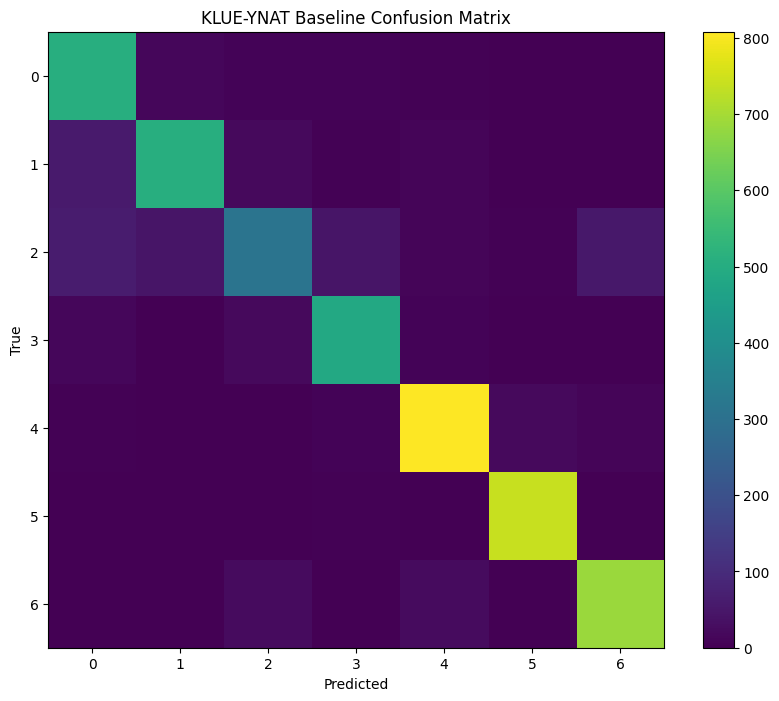

In [16]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(true_labels, pred_labels)

plt.figure(figsize=(10, 8))
plt.imshow(cm)
plt.title("KLUE-YNAT Baseline Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.show()

In [17]:
from sklearn.metrics import classification_report

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=label_feature.names,
        digits=4
    )
)

              precision    recall  f1-score   support

        IT과학     0.7785    0.9319    0.8483       543
          경제     0.8862    0.8364    0.8605       605
          사회     0.7974    0.5835    0.6739       533
        생활문화     0.8717    0.9140    0.8923       535
          세계     0.9298    0.9417    0.9357       858
         스포츠     0.9598    0.9815    0.9705       755
          정치     0.9073    0.9269    0.9170       739

    accuracy                         0.8857      4568
   macro avg     0.8758    0.8737    0.8712      4568
weighted avg     0.8851    0.8857    0.8825      4568



In [18]:
class_names = label_feature.names

errors = []

for true_idx in range(len(class_names)):
    for pred_idx in range(len(class_names)):
        if true_idx != pred_idx:
            count = cm[true_idx, pred_idx]
            rate = count / cm[true_idx].sum()

            errors.append({
                "true": class_names[true_idx],
                "pred": class_names[pred_idx],
                "count": count,
                "rate": rate
            })

errors = sorted(errors, key=lambda x: x["count"], reverse=True)

for x in errors[:10]:
    print(
        f"{x['true']:6s} -> {x['pred']:6s} | "
        f"{x['count']:4d}개 | {x['rate']:.2%}"
    )

사회     -> IT과학   |   62개 | 11.63%
경제     -> IT과학   |   57개 | 9.42%
사회     -> 정치     |   53개 | 9.94%
사회     -> 경제     |   46개 | 8.63%
사회     -> 생활문화   |   46개 | 8.63%
정치     -> 세계     |   25개 | 3.38%
정치     -> 사회     |   24개 | 3.25%
세계     -> 스포츠    |   21개 | 2.45%
경제     -> 사회     |   20개 | 3.31%
생활문화   -> 사회     |   20개 | 3.74%


# Day 1 Experiment Log

Built the classification baseline and reserved the hold-out split for final evaluation.


# Day 2 - Controlled Experiments and Error Analysis

Compare training settings and inspect representative classification errors.


In [19]:
import time

set_seed(SEED)


def create_model():
    return AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(label_feature.names),
        id2label={
            i: name for i, name in enumerate(label_feature.names)
        },
        label2id={
            name: i for i, name in enumerate(label_feature.names)
        }
    )


In [20]:
def run_experiment(
    learning_rate,
    output_dir,
    tokenized_data,
    batch_size=16,
    max_length=128
):
    # 재현성을 위한 시드 고정
    set_seed(SEED)

    # GPU memory 초기화
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    # 2. 공정한 실험을 위한 새 모델 생성
    model = create_model()

    # 파라미터 개수 측정
    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    # 학습 인자들
    training_args = TrainingArguments(
        output_dir=output_dir,

        learning_rate=learning_rate,

        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=32,

        num_train_epochs=1,
        weight_decay=0.01,

        eval_strategy="epoch",
        save_strategy="no",

        report_to="none",

        seed=SEED,
        data_seed=SEED,

        fp16=torch.cuda.is_available(),
    )

    # 학습기
    trainer = Trainer(
        model=model,
        args=training_args,

        train_dataset=tokenized_data["train"],
        eval_dataset=tokenized_data["validation"],

        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )

    # 학습 시간 측정
    start_time = time.perf_counter()

    trainer.train()

    training_time = time.perf_counter() - start_time

    # 평가
    eval_result = trainer.evaluate()

    # GPU 메모리 사용 최고점 기록
    if torch.cuda.is_available():
        peak_gpu_memory = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
        )
    else:
        peak_gpu_memory = 0.0

    # 실험 정보
    result = {
        "seed": SEED,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "max_length": max_length,

        "total_params": total_params,
        "trainable_params": trainable_params,

        "eval_loss": eval_result["eval_loss"],
        "accuracy": eval_result["eval_accuracy"],
        "macro_f1": eval_result["eval_macro_f1"],
        "weighted_f1": eval_result["eval_weighted_f1"],

        "training_time_sec": training_time,
        "peak_gpu_memory_gb": peak_gpu_memory,
    }

    return result, trainer

In [21]:
tokenized_64 = create_tokenized_dataset(64)
tokenized_128 = create_tokenized_dataset(128)
tokenized_256 = create_tokenized_dataset(256)

baseline_result, trainer = run_experiment(
    learning_rate=2e-5,
    output_dir="./day2_baseline",
    tokenized_data=tokenized_128,
    batch_size=16,
    max_length=128
)

baseline_result

Map:   0%|          | 0/41110 [00:00<?, ? examples/s]

Map:   0%|          | 0/4568 [00:00<?, ? examples/s]

Map:   0%|          | 0/9107 [00:00<?, ? examples/s]

Map:   0%|          | 0/41110 [00:00<?, ? examples/s]

Map:   0%|          | 0/4568 [00:00<?, ? examples/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather al

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.763517,0.685142,0.883100,0.869274,0.880305


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'seed': 378,
 'learning_rate': 2e-05,
 'batch_size': 16,
 'max_length': 128,
 'total_params': 110623495,
 'trainable_params': 110623495,
 'eval_loss': 0.6851416230201721,
 'accuracy': 0.8830998248686515,
 'macro_f1': 0.8692743276676191,
 'weighted_f1': 0.8803046537596356,
 'training_time_sec': 235.04298302899997,
 'peak_gpu_memory_gb': 3.3409008979797363}

In [22]:
import pandas as pd

predictions = trainer.predict(
    tokenized_dataset["validation"]
)

pred_labels = np.argmax(
    predictions.predictions,
    axis=1
)

true_labels = predictions.label_ids

validation_df = dataset["validation"].to_pandas()

# 실제 label 추가
validation_df["true_label"] = [
    label_feature.names[i]
    for i in true_labels
]

# 예측 label 추가
validation_df["pred_label"] = [
    label_feature.names[i]
    for i in pred_labels
]

# 오분류만 추출
error_df = validation_df[
    validation_df["true_label"] != validation_df["pred_label"]
].copy()

print(f"Validation samples : {len(validation_df):,}")
print(f"Misclassified      : {len(error_df):,}")
print(f"Error rate         : {len(error_df) / len(validation_df):.2%}")

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Validation samples : 4,568
Misclassified      : 534
Error rate         : 11.69%


In [23]:
class_error = (
    error_df["true_label"]
    .value_counts()
    .to_frame("errors")
)

class_total = (
    validation_df["true_label"]
    .value_counts()
    .to_frame("total")
)

class_error = class_total.join(
    class_error,
    how="left"
).fillna(0)

class_error["error_rate"] = (
    class_error["errors"] /
    class_error["total"]
)

class_error = class_error.sort_values(
    "error_rate",
    ascending=False
)

class_error

,total,errors,error_rate
true_label,,,
사회,533,212,0.397749
경제,605,101,0.166942
IT과학,543,54,0.099448
생활문화,535,46,0.085981
세계,858,58,0.067599
정치,739,48,0.064953
스포츠,755,15,0.019868


In [24]:
confusion_pairs = (
    error_df
    .groupby(["true_label", "pred_label"])
    .size()
    .reset_index(name="errors")
)

confusion_pairs["true_class_total"] = (
    confusion_pairs["true_label"]
    .map(
        validation_df["true_label"].value_counts()
    )
)

confusion_pairs["error_rate"] = (
    confusion_pairs["errors"] /
    confusion_pairs["true_class_total"]
)

confusion_pairs = confusion_pairs.sort_values(
    "error_rate",
    ascending=False
)

confusion_pairs.head(20)

,true_label,pred_label,errors,true_class_total,error_rate
13,사회,경제,57,533,0.106942
12,사회,IT과학,49,533,0.091932
6,경제,IT과학,55,605,0.090909
14,사회,생활문화,46,533,0.086304
17,사회,정치,44,533,0.082552
0,IT과학,경제,22,543,0.040516
20,생활문화,사회,19,535,0.035514
38,정치,세계,25,739,0.033829
1,IT과학,사회,18,543,0.033149
7,경제,사회,20,605,0.033058


In [25]:
pairs = [
    ("정치", "사회"),
    ("경제", "사회"),
    ("생활문화", "사회"),
    ("IT과학", "사회")
]

for true_label, pred_label in pairs:
    print(f"{true_label} -> {pred_label}")
    
    samples = error_df[
        (error_df["true_label"] == true_label) &
        (error_df["pred_label"] == pred_label)
    ][["title", "true_label", "pred_label"]]

    display(samples.head(20))

정치 -> 사회


,title,true_label,pred_label
219,박원순 시장 아부다비 루브르 박물관 방문,정치,사회
507,이산가족 76% 전면적 생사확인 가장 시급히 추진돼야종합,정치,사회
653,與 23일 봉하마을 총집결…盧 서거 8주기에 최대규모 추도식,정치,사회
711,제21대 국회의원선거 선거방송심의위원회 위원 위촉식,정치,사회
827,김의겸 진보개혁 성향 신문기자 출신…최순실 특종 명성 종합,정치,사회
1102,언론사 협력 팩트체크 정치적 불편 부당성이 선결과제,정치,사회
1633,민주노총 대의원대회,정치,사회
1900,이효성 방통위원장 평창 UHD방송 준비상황 점검,정치,사회
2073,일본군 위안부 한일 양국만의 문제 아냐…관점 확대해야,정치,사회
2708,특검 전담팀 꾸려 최순실 일가 재산 추적…제보 많다종합,정치,사회


경제 -> 사회


,title,true_label,pred_label
284,래싱업체 등 한진 선박 작업거부 철회…항만공사가 대신 지급,경제,사회
489,네이버 D2 스타트업 팩토리 방문한 방송통신위원장,경제,사회
1206,부산항 북항 크루즈 부두 넓힌다…대형선박 수용,경제,사회
1492,한낮 카풀 놓고 서울시스타트업계 충돌…위법성 논란종합,경제,사회
1917,삼성전자 분리공시제 우려 있으나 정부 정책 따를 것,경제,사회
1937,英 공직자 경제통계 사전열람 막자 시장 이상변동 줄어,경제,사회
2172,한진그룹 3세 조원태 대한항공 총괄 부사장에 선임,경제,사회
2422,게시판 미래부 KGlobal 스타트업 공모전 출범식,경제,사회
2524,2차례 정전으로 일찍 문 닫은 창조경제 박람회종합,경제,사회
2636,SKT 010 번호 94.3% 사용 고갈 우려…정부 문제없다,경제,사회


생활문화 -> 사회


,title,true_label,pred_label
46,편혜영 내부고발 이야기 쓰고 싶었죠,생활문화,사회
124,게시판 방통위 2018 해외 우수 공동제작 대상 공모,생활문화,사회
269,국가지식재산위 IP 서밋 컨퍼런스 개최,생활문화,사회
895,감빵생활 실상은…어느 서울대생의 수감기,생활문화,사회
1146,가야금 명인 황병기 별세…향년 82세2보,생활문화,사회
1298,방심위 이달의 좋은 프로그램 12편 시상,생활문화,사회
1491,제주 우도 교통대란 ③ 공동체 지속 위한 과감한 합의 절실,생활문화,사회
1824,경찰 소재 영화ㆍ방송인 맞는 민갑룡 경찰청장,생활문화,사회
1833,최강한파 무더기결항 제주공항 인근 호텔 숙박대란,생활문화,사회
2124,환동해권 크루즈 노선 신설…부산관광 체질 바꾼다,생활문화,사회


IT과학 -> 사회


,title,true_label,pred_label
43,유튜브 내달 2일까지 콘텐츠 창작 지원공간 운영종합,IT과학,사회
53,게시판 인천서 방통위 드론 영상 공모전 시상식,IT과학,사회
346,가스공사 엑손모빌 등과 기술교류 워크숍 개최,IT과학,사회
355,랜섬웨어 피해 웹호스팅 업체 해커와 13억원에 협상 타결종합,IT과학,사회
1087,한글도메인 점유율 한자릿수로 뚝…이용률은 0.3% 불과,IT과학,사회
1113,카이스트 융합형 인재 기른다…내년 무학과 융합기초학부 도입,IT과학,사회
1446,부울경 LGU 휴대전화 40분간 먹통…신고 잇따라종합,IT과학,사회
1676,김성태 포털 횡포 방지…사이버골목상권보호특별법 추진,IT과학,사회
1834,인터넷진흥원 호남권 청소년 대상 정보보호인력 양성 프로그램,IT과학,사회
1899,참화 부른 보잉의 늑장대응…이제 와서 열흘내 업그레이드종합,IT과학,사회


In [26]:
it_errors = error_df[
    error_df["true_label"] == "IT과학"
][["title", "true_label", "pred_label"]]

display(it_errors.head(50))

sports_errors = error_df[
    error_df["true_label"] == "스포츠"
][["title", "true_label", "pred_label"]]

display(sports_errors)

,title,true_label,pred_label
43,유튜브 내달 2일까지 콘텐츠 창작 지원공간 운영종합,IT과학,사회
53,게시판 인천서 방통위 드론 영상 공모전 시상식,IT과학,사회
148,카카오 스마트 모빌리티 성장방법 고민…분사 결정된 바 없어,IT과학,경제
198,트럼프 랜섬웨어도 등장…한국 맞춤형 공격 점입가경,IT과학,세계
247,靑 비아그라는 고산병 치료제…순방 대비해 준비,IT과학,정치
255,KT 프리미엄 요금제 고객 혜택 확대,IT과학,경제
346,가스공사 엑손모빌 등과 기술교류 워크숍 개최,IT과학,사회
355,랜섬웨어 피해 웹호스팅 업체 해커와 13억원에 협상 타결종합,IT과학,사회
607,게시판 STEPI 에티오피아 STIC 역량강화 연수과정,IT과학,세계
828,중국서 베껴쓰기 방학숙제 대신해주는 로봇 등장 화제,IT과학,세계


,title,true_label,pred_label
228,베트남영웅 박항서호 금의환향…수천명 환영인파에 카퍼레이드,스포츠,세계
398,조선중앙통신 북한 선수단 입촌식 보도,스포츠,정치
620,넥슨 빠져도… 올해 지스타 작년 이상 규모 될 듯,스포츠,경제
774,SKT 5G로 한영 간 원격축구교실…손흥민 개인 지도,스포츠,IT과학
1196,게시판 서울시 어린이 야구교실 내달 8일 개강,스포츠,생활문화
1872,팬텀싱어 우승팀 포르테 디 콰트로 14개 도시서 투어공연,스포츠,생활문화
1880,U프로야구·골프 TV로 본다…Utv용 중계 서비스 출시,스포츠,IT과학
2226,LG 공식 사과 사인 훔치기 논란 불미스러운 일종합,스포츠,사회
2488,MS IT월드컵 한국대표 선발…세계 무대서 겨룬다종합,스포츠,IT과학
2894,세계 첫 AI 축구 월드컵에 쏠린 눈,스포츠,IT과학


In [27]:
experiments = [
    {
        "learning_rate": 2e-5,
        "batch_size": 8,
        "max_length": 128,
        "tokenized_data": tokenized_128,
        "output_dir": "./exp_batch_8"
    },
    {
        "learning_rate": 2e-5,
        "batch_size": 32,
        "max_length": 128,
        "tokenized_data": tokenized_128,
        "output_dir": "./exp_batch_32"
    },

    {
        "learning_rate": 1e-5,
        "batch_size": 16,
        "max_length": 128,
        "tokenized_data": tokenized_128,
        "output_dir": "./exp_lr_1e-5"
    },
    {
        "learning_rate": 3e-5,
        "batch_size": 16,
        "max_length": 128,
        "tokenized_data": tokenized_128,
        "output_dir": "./exp_lr_3e-5"
    },

    {
        "learning_rate": 2e-5,
        "batch_size": 16,
        "max_length": 64,
        "tokenized_data": tokenized_64,
        "output_dir": "./exp_maxlen_64"
    },
    {
        "learning_rate": 2e-5,
        "batch_size": 16,
        "max_length": 256,
        "tokenized_data": tokenized_256,
        "output_dir": "./exp_maxlen_256"
    }
]

results = []

for i, exp in enumerate(experiments, 1):
    print(f"Experiment {i}/6")
    print(exp)

    result, _ = run_experiment(
        learning_rate=exp["learning_rate"],
        batch_size=exp["batch_size"],
        max_length=exp["max_length"],
        tokenized_data=exp["tokenized_data"],
        output_dir=exp["output_dir"]
    )

    results.append(result)



Experiment 1/6
{'learning_rate': 2e-05, 'batch_size': 8, 'max_length': 128, 'tokenized_data': DatasetDict({
    train: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'attention_mask'],
        num_rows: 41110
    })
    validation: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'attention_mask'],
        num_rows: 4568
    })
    test: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'attention_mask'],
        num_rows: 9107
    })
}), 'output_dir': './exp_batch_8'}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather al

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.710781,0.696432,0.880035,0.865456,0.877035


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


...

Experiment 6/6
{'learning_rate': 2e-05, 'batch_size': 16, 'max_length': 256, 'tokenized_data': DatasetDict({
    train: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'attention_mask'],
        num_rows: 41110
    })
    validation: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'attention_mask'],
        num_rows: 4568
    })
    test: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'attention_mask'],
        num_rows: 9107
    })
}), 'output_dir': './exp_maxlen_256'}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather al

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.763517,0.685142,0.883100,0.869274,0.880305


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [28]:
search_results_df = pd.DataFrame(
    [baseline_result] + results
)

search_results_df = search_results_df.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

display(search_results_df)


,seed,learning_rate,batch_size,max_length,total_params,trainable_params,eval_loss,accuracy,macro_f1,weighted_f1,training_time_sec,peak_gpu_memory_gb
0,378,0.00002,16,128,110623495,110623495,0.685142,0.883100,0.869274,0.880305,235.042983,3.340901
1,378,0.00002,16,64,110623495,110623495,0.685142,0.883100,0.869274,0.880305,234.516564,4.991545
2,378,0.00002,16,256,110623495,110623495,0.685142,0.883100,0.869274,0.880305,234.939385,4.992033
3,378,0.00003,16,128,110623495,110623495,0.682428,0.882662,0.868566,0.879782,236.889037,4.993760
4,378,0.00002,32,128,110623495,110623495,0.699580,0.881130,0.866649,0.877670,160.603323,5.008392
5,378,0.00002,8,128,110623495,110623495,0.696432,0.880035,0.865456,0.877035,416.540403,3.753986
6,378,0.00001,16,128,110623495,110623495,0.721030,0.880254,0.864968,0.876630,234.365459,4.991538


# Day 2 Experiment Log

Screened the main training settings with a fixed seed and saved the best configuration.


# Day 3 - Model Size and Efficiency Trade-off

Compare model efficiency and train the selected configuration for the final test.


In [29]:
train_titles = dataset["train"]["title"]

token_lengths = [
    len(tokenizer.encode(title, add_special_tokens=True))
    for title in train_titles
]

print(f"평균: {np.mean(token_lengths):.2f}")
print(f"중앙값: {np.median(token_lengths):.2f}")
print(f"최대: {np.max(token_lengths)}")
print(f"90%: {np.percentile(token_lengths, 90):.2f}")
print(f"95%: {np.percentile(token_lengths, 95):.2f}")
print(f"99%: {np.percentile(token_lengths, 99):.2f}")

for max_len in [64, 128, 256]:
    ratio = np.mean(np.array(token_lengths) > max_len)

    print(
        f"max_length={max_len}: "
        f"{ratio * 100:.2f}% 초과"
    )

평균: 15.40
중앙값: 15.00
최대: 30
90%: 19.00
95%: 20.00
99%: 23.00
max_length=64: 0.00% 초과
max_length=128: 0.00% 초과
max_length=256: 0.00% 초과


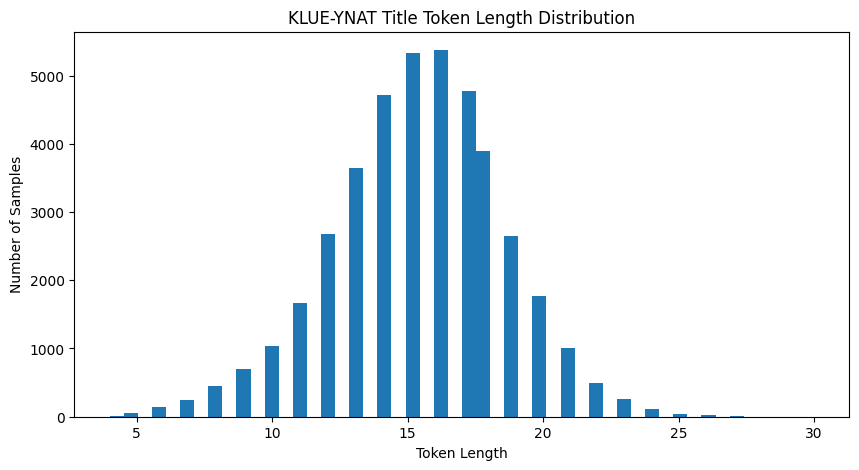

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(token_lengths, bins=50)

plt.xlabel("Token Length")
plt.ylabel("Number of Samples")
plt.title("KLUE-YNAT Title Token Length Distribution")

plt.show()

In [31]:
models = [
    "klue/roberta-small",
    "klue/roberta-base",
]

In [32]:
def create_model(model_name):
    return AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(label_feature.names),
        id2label={
            i: name for i, name in enumerate(label_feature.names)
        },
        label2id={
            name: i for i, name in enumerate(label_feature.names)
        }
    )

In [33]:
def run_experiment(
    model_name,
    learning_rate,
    output_dir,
    tokenized_data,
    batch_size=16,
    max_length=64
):
    # 재현성을 위한 시드 고정
    set_seed(SEED)

    # GPU memory 초기화
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    # 공정한 실험을 위한 새 모델 생성
    model = create_model(model_name)

    # 파라미터 개수 측정
    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    # 학습 인자
    training_args = TrainingArguments(
        output_dir=output_dir,

        learning_rate=learning_rate,

        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=32,

        num_train_epochs=1,
        weight_decay=0.01,

        eval_strategy="epoch",
        save_strategy="no",

        report_to="none",

        seed=SEED,
        data_seed=SEED,

        fp16=torch.cuda.is_available(),
    )

    # 학습기
    trainer = Trainer(
        model=model,
        args=training_args,

        train_dataset=tokenized_data["train"],
        eval_dataset=tokenized_data["validation"],

        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )

    # 학습 시간 측정
    start_time = time.perf_counter()

    trainer.train()

    training_time = time.perf_counter() - start_time

    # 평가
    eval_result = trainer.evaluate()

    # GPU 메모리 최고점
    if torch.cuda.is_available():
        peak_gpu_memory = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
        )
    else:
        peak_gpu_memory = 0.0

    # 실험 결과
    result = {
        "seed": SEED,
        "model": model_name,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "max_length": max_length,

        "total_params": total_params,
        "trainable_params": trainable_params,

        "eval_loss": eval_result["eval_loss"],
        "accuracy": eval_result["eval_accuracy"],
        "macro_f1": eval_result["eval_macro_f1"],
        "weighted_f1": eval_result["eval_weighted_f1"],

        "training_time_sec": training_time,
        "peak_gpu_memory_gb": peak_gpu_memory,
    }

    return result

In [34]:
model_scale_results = []

for model_name in models:
    print(f"Experiment: {model_name}")

    result = run_experiment(
        model_name=model_name,
        learning_rate=3e-5,
        output_dir=f"./day3_{model_name.split('/')[-1]}",
        tokenized_data=tokenized_64,
        batch_size=16,
        max_length=64
    )

    model_scale_results.append(result)



Experiment: klue/roberta-small


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/273M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-small
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather a

...

Experiment: klue/roberta-base


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather al

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.763161,0.682428,0.882662,0.868566,0.879782


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [35]:
search_results_df = pd.DataFrame(
    [baseline_result] + results
)

search_results_df = search_results_df.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

display(search_results_df)


,seed,learning_rate,batch_size,max_length,total_params,trainable_params,eval_loss,accuracy,macro_f1,weighted_f1,training_time_sec,peak_gpu_memory_gb
0,378,0.00002,16,128,110623495,110623495,0.685142,0.883100,0.869274,0.880305,235.042983,3.340901
1,378,0.00002,16,64,110623495,110623495,0.685142,0.883100,0.869274,0.880305,234.516564,4.991545
2,378,0.00002,16,256,110623495,110623495,0.685142,0.883100,0.869274,0.880305,234.939385,4.992033
3,378,0.00003,16,128,110623495,110623495,0.682428,0.882662,0.868566,0.879782,236.889037,4.993760
4,378,0.00002,32,128,110623495,110623495,0.699580,0.881130,0.866649,0.877670,160.603323,5.008392
5,378,0.00002,8,128,110623495,110623495,0.696432,0.880035,0.865456,0.877035,416.540403,3.753986
6,378,0.00001,16,128,110623495,110623495,0.721030,0.880254,0.864968,0.876630,234.365459,4.991538


# Final Training - Best Configuration and Hold-out Test


In [36]:
best_screening = search_results_df.iloc[0].to_dict()
best_max_length = int(best_screening["max_length"])
tokenized_by_length = {
    64: tokenized_64,
    128: tokenized_128,
    256: tokenized_256,
}
final_data = tokenized_by_length[best_max_length]
columns_to_remove = [
    column for column in ["title", "guid", "url", "date"]
    if column in final_data["train"].column_names
]
final_data = final_data.remove_columns(columns_to_remove)

print("Selected configuration:", best_screening)
print("Final train/dev/test sizes:", [len(final_data[key]) for key in ["train", "validation", "test"]])

Selected configuration: {'seed': 378.0, 'learning_rate': 2e-05, 'batch_size': 16.0, 'max_length': 128.0, 'total_params': 110623495.0, 'trainable_params': 110623495.0, 'eval_loss': 0.6851416230201721, 'accuracy': 0.8830998248686515, 'macro_f1': 0.8692743276676191, 'weighted_f1': 0.8803046537596356, 'training_time_sec': 235.04298302899997, 'peak_gpu_memory_gb': 3.3409008979797363}
Final train/dev/test sizes: [41110, 4568, 9107]


In [37]:
import os
import json
from transformers import EarlyStoppingCallback

final_model = create_model("klue/roberta-base")
final_output_dir = "/kaggle/working/week1_final_model"

final_args = TrainingArguments(
    output_dir=final_output_dir,
    learning_rate=float(best_screening["learning_rate"]),
    per_device_train_batch_size=int(best_screening["batch_size"]),
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    fp16=torch.cuda.is_available(),
)

final_trainer = Trainer(
    model=final_model,
    args=final_args,
    train_dataset=final_data["train"],
    eval_dataset=final_data["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
start_time = time.perf_counter()
final_trainer.train()
final_training_time = time.perf_counter() - start_time
peak_gpu_memory = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
    if torch.cuda.is_available() else 0.0
)

final_trainer.save_model(final_output_dir)
tokenizer.save_pretrained(final_output_dir)
print(f"Final training time: {final_training_time:.2f} sec")
print(f"Peak GPU memory: {peak_gpu_memory:.3f} GB")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather al

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.784933,0.740014,0.872154,0.854473,0.867308
2,0.567237,0.693472,0.881567,0.867357,0.878723
3,0.432930,0.722552,0.880911,0.867487,0.879071


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


...

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final training time: 709.31 sec
Peak GPU memory: 4.994 GB


In [38]:
test_metrics = final_trainer.evaluate(
    eval_dataset=final_data["test"],
    metric_key_prefix="test"
)
test_predictions = final_trainer.predict(final_data["test"])
test_pred_labels = np.argmax(test_predictions.predictions, axis=-1)
test_true_labels = test_predictions.label_ids

final_test_df = dataset["test"].to_pandas()
final_test_df["true_label"] = [label_feature.names[i] for i in test_true_labels]
final_test_df["pred_label"] = [label_feature.names[i] for i in test_pred_labels]
test_error_df = final_test_df[final_test_df["true_label"] != final_test_df["pred_label"]].copy()

final_results = {
    "model": "klue/roberta-base",
    "seed": SEED,
    "epochs": 3,
    "best_screening_config": best_screening,
    "test_metrics": test_metrics,
    "training_time_sec": final_training_time,
    "peak_gpu_memory_gb": peak_gpu_memory,
    "train_size": len(final_data["train"]),
    "dev_size": len(final_data["validation"]),
    "test_size": len(final_data["test"]),
}

os.makedirs("/kaggle/working/week1_results", exist_ok=True)
search_results_df.to_csv("/kaggle/working/week1_results/screening_results.csv", index=False)
test_error_df.to_csv("/kaggle/working/week1_results/test_errors.csv", index=False, encoding="utf-8-sig")
with open("/kaggle/working/week1_results/final_results.json", "w", encoding="utf-8") as file:
    json.dump(final_results, file, ensure_ascii=False, indent=2, default=float)
with open("/kaggle/working/week1_results/final_config.json", "w", encoding="utf-8") as file:
    json.dump({"model_name": "klue/roberta-base", "max_length": best_max_length, "seed": SEED, "epochs": 3}, file, indent=2)

print("Hold-out test metrics:", test_metrics)
print("Test errors:", len(test_error_df))
print("Saved model:", final_output_dir)
print("Saved results: /kaggle/working/week1_results")


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Hold-out test metrics: {'test_loss': 0.7739103436470032, 'test_accuracy': 0.8695508949159987, 'test_macro_f1': 0.8689306917246797, 'test_weighted_f1': 0.869647479227054, 'test_runtime': 11.5068, 'test_samples_per_second': 791.446, 'test_steps_per_second': 12.427, 'epoch': 3.0}
Test errors: 1188
Saved model: /kaggle/working/week1_final_model
Saved results: /kaggle/working/week1_results


# Day 3 Experiment Log

The selected configuration reached Macro-F1 0.8689 on the hold-out test after three training epochs. The final model and test error cases were saved for review.
